<a href="https://colab.research.google.com/github/ibrahimu-shaffy/COU07506-labs_240242491389/blob/main/COU07506_Week05_240242491389.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



## DIGITAL SIGNAL PROCESSING

**Module Code:** COU 07506

**Student Name:** SHAFIYU SWALEHE IBRAHIMU

**Registration Number:** 240242491389


# WEEK 05 — LAB 2

## Implementing the FFT

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Pre-lab Questions

### (a) Compute the 4-point DFT of {1, 0, -1, 0}.

Given:

$$
x(n)=[1,0,-1,0]
$$

The DFT formula is:

$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N}
$$

For N = 4:

$$
X(0)=1+0-1+0=0
$$

$$
X(1)=1-(-1)=2
$$

$$
X(2)=1-1=0
$$

$$
X(3)=1-(-1)=2
$$

Therefore:

$$
X(k)=[0,2,0,2]
$$

### (b) Write the 8-point bit-reversed index order.

| Index | Binary | Reversed | New Index |
|---|---|---|---|
| 0 | 000 | 000 | 0 |
| 1 | 001 | 100 | 4 |
| 2 | 010 | 010 | 2 |
| 3 | 011 | 110 | 6 |
| 4 | 100 | 001 | 1 |
| 5 | 101 | 101 | 5 |
| 6 | 110 | 011 | 3 |
| 7 | 111 | 111 | 7 |

Bit-reversed order:

$$
[0,4,2,6,1,5,3,7]
$$

### (c) Complex multiplications for a 1024-point
DFT and radix-2 FFT.

Direct DFT:

$$
N^2=1024^2=1,048,576
$$

Radix-2 FFT:

$$
\frac{N}{2}\log_2N
$$

$$
=\frac{1024}{2}\times10=5120
$$

Therefore, the FFT requires significantly fewer
complex multiplications than the direct DFT.

## Task 5.1 — DFT by Matrix

This experiment computes the Discrete Fourier
Transform using the matrix definition and
compares the results with NumPy FFT.

In [63]:
def dft_matrix(N):
    n = np.arange(N)
    return np.exp(-2j*np.pi*np.outer(n, n)/N)

x = np.array([0, 1, 2, 3])

X = dft_matrix(4) @ x

print("DFT Result:", np.round(X, 4))

print("Matches NumPy FFT:", np.allclose(X, np.fft.fft(x)))

# Inverse DFT
x_back = (dft_matrix(4).conj() @ X) / 4

print("Recovered Signal:", np.round(x_back.real, 6))

DFT Result: [ 6.+0.j -2.+2.j -2.-0.j -2.-2.j]
Matches NumPy FFT: True
Recovered Signal: [0. 1. 2. 3.]


DFT Result: [0.+0.j 2.+0.j 0.-0.j 2.+0.j]
Matches NumPy FFT: True


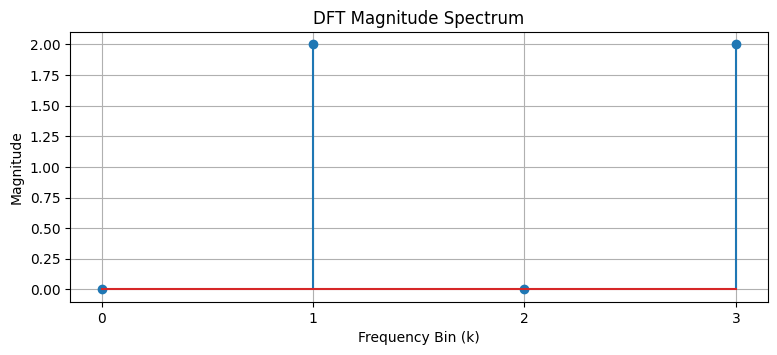

In [64]:
x = np.array([1, 0, -1, 0])

X = dft_matrix(4) @ x

print("DFT Result:", np.round(X, 4))
print("Matches NumPy FFT:", np.allclose(X, np.fft.fft(x)))

plt.stem(np.arange(4), np.abs(X))
plt.title("DFT Magnitude Spectrum")
plt.xlabel("Frequency Bin (k)")
plt.ylabel("Magnitude")
plt.xticks(np.arange(4))
plt.grid(True)
plt.show()

## Observation

The DFT matrix produces the same results as
the NumPy FFT function.

The inverse DFT successfully reconstructs
the original input signal.

The pre-lab result [0, 2, 0, 2] is confirmed
by the matrix-based DFT computation.

## Task 5.2 — Bit Reversal

This experiment implements bit-reversed indexing,
which is used to rearrange input samples before
performing the radix-2 FFT algorithm.

In [65]:
def bit_reverse_indices(N):
    bits = int(np.log2(N))
    return np.array([
        int(format(i, f"0{bits}b")[::-1], 2)
        for i in range(N)
    ])

print("Original indices:", np.arange(8))
print("Bit-reversed indices:", bit_reverse_indices(8))

Original indices: [0 1 2 3 4 5 6 7]
Bit-reversed indices: [0 4 2 6 1 5 3 7]


## Observation

The bit-reversal function successfully rearranges
the eight indices into the following order:

[0, 4, 2, 6, 1, 5, 3, 7]

The result agrees with the pre-lab calculation.
Bit reversal prepares the input sequence for
the iterative radix-2 FFT butterfly operations.

## Task 5.3 — Iterative Radix-2 FFT

This experiment implements the radix-2
Decimation-in-Time FFT algorithm using bit
reversal and butterfly operations.

The results are compared with NumPy FFT
to verify the correctness of the algorithm.

In [66]:
def fft_iterative(x, show_steps=False):

    x = np.asarray(x, dtype=complex)
    N = len(x)

    X = x[bit_reverse_indices(N)].copy()

    if show_steps:
        print("Stage 0 - Bit reversal:", X)

    size = 2

    while size <= N:

        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size)

        for start in range(0, N, size):

            top = X[start:start+half].copy()
            bot = X[start+half:start+size] * W

            X[start:start+half] = top + bot
            X[start+half:start+size] = top - bot

        if show_steps:
            print(f"Stage size {size}:", np.round(X, 4))

        size *= 2

    return X

x = np.random.randn(1024)

print("Matches NumPy FFT:",
      np.allclose(fft_iterative(x), np.fft.fft(x)))

Matches NumPy FFT: True


In [67]:
x = np.array([0, 1, 2, 3])

X = fft_iterative(x, show_steps=True)

print("Final FFT:", np.round(X, 4))
print("NumPy FFT:", np.fft.fft(x))

Stage 0 - Bit reversal: [0.+0.j 2.+0.j 1.+0.j 3.+0.j]
Stage size 2: [ 2.+0.j -2.+0.j  4.+0.j -2.+0.j]
Stage size 4: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
Final FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
NumPy FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]


## Observation

The iterative radix-2 FFT successfully computes
the frequency-domain representation of the
input signal.

The algorithm first rearranges the samples
using bit reversal and then performs butterfly
operations in successive stages.

For the four-point input, two butterfly stages
are required.

The final results match the NumPy FFT output,
confirming the correctness of the implementation.

## Task 5.4 — How Much Faster?

This experiment compares the computational
performance of the direct DFT, iterative FFT
and NumPy FFT for different input sizes.

The theoretical computational complexities are:

Direct DFT:

$$
O(N^2)
$$

Fast Fourier Transform:

$$
O(N\log_2N)
$$

N = 64: Completed
N = 128: Completed
N = 256: Completed
N = 512: Completed
N = 1024: Completed
N = 2048: Completed
N = 4096: Completed


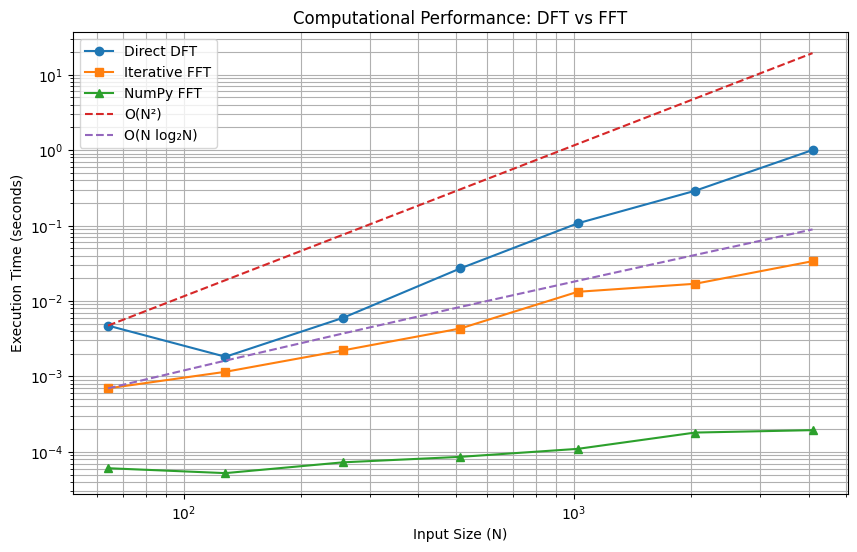

In [68]:
N_values = 2**np.arange(6, 13)

dft_times = []
fft_times = []
numpy_times = []

for N in N_values:

    x = np.random.randn(N)

    # Direct DFT
    start = time.perf_counter()
    dft_matrix(N) @ x
    dft_times.append(time.perf_counter() - start)

    # Iterative FFT
    start = time.perf_counter()
    fft_iterative(x)
    fft_times.append(time.perf_counter() - start)

    # NumPy FFT
    start = time.perf_counter()
    np.fft.fft(x)
    numpy_times.append(time.perf_counter() - start)

    print(f"N = {N}: Completed")

# Theoretical complexity curves
N_squared = dft_times[0] * (N_values/N_values[0])**2

N_logN = fft_times[0] * (
    N_values*np.log2(N_values)
) / (N_values[0]*np.log2(N_values[0]))

# Plot results
plt.figure(figsize=(10, 6))

plt.loglog(N_values, dft_times, 'o-', label="Direct DFT")
plt.loglog(N_values, fft_times, 's-', label="Iterative FFT")
plt.loglog(N_values, numpy_times, '^-', label="NumPy FFT")

plt.loglog(N_values, N_squared, '--', label="O(N²)")
plt.loglog(N_values, N_logN, '--', label="O(N log₂N)")

plt.xlabel("Input Size (N)")
plt.ylabel("Execution Time (seconds)")
plt.title("Computational Performance: DFT vs FFT")
plt.legend()
plt.grid(True, which="both")
plt.show()

## Observation

The execution time of the direct DFT increases
rapidly as the input size increases.

The iterative FFT requires less computation
for large input sizes because its complexity
is O(N log N).

NumPy FFT provides better performance due to
its optimized implementation.

The results demonstrate the computational
advantage of FFT over the direct DFT.

## Task 5.5 — Zero-padding and the DTFT

This experiment investigates the effect of
zero-padding on the DFT magnitude spectrum.

The input signal is:

$$
x(n)=[1,1,1,1]
$$

The theoretical DTFT magnitude is:

$$
|X(e^{j\omega})|=
\left|\frac{\sin(2\omega)}{\sin(\omega/2)}\right|
$$

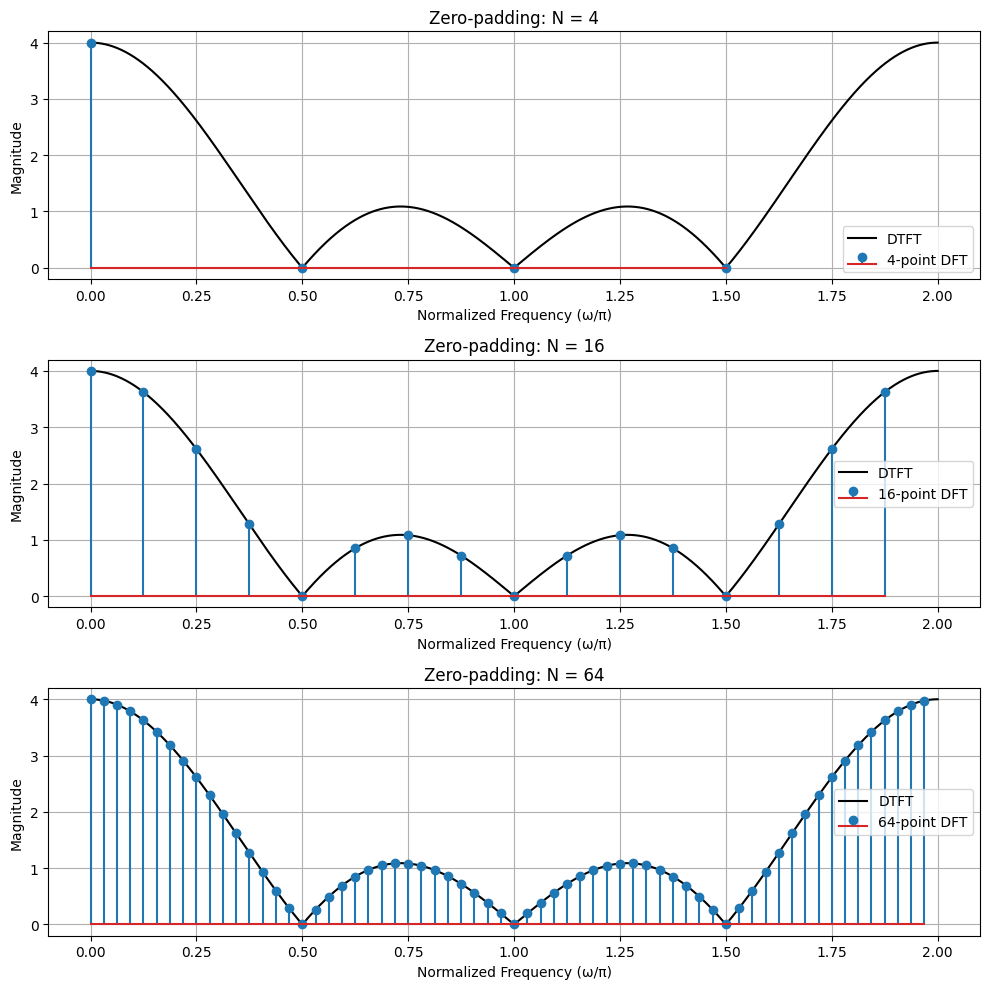

In [69]:
x = np.array([1, 1, 1, 1])

w = np.linspace(0, 2*np.pi, 2000)

# Theoretical DTFT
X_dtft = np.abs(
    np.exp(-1j*np.outer(w, np.arange(len(x)))) @ x
)

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

for ax, N in zip(axes, [4, 16, 64]):

    X = np.fft.fft(x, n=N)

    wk = 2*np.pi*np.arange(N)/N

    ax.plot(w/np.pi, X_dtft, label="DTFT", color="black")

    ax.stem(wk/np.pi, np.abs(X), label=f"{N}-point DFT")

    ax.set_title(f"Zero-padding: N = {N}")
    ax.set_xlabel("Normalized Frequency (ω/π)")
    ax.set_ylabel("Magnitude")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## Observation

The 4-point DFT provides fewer frequency samples.

The 16-point and 64-point DFTs provide more
frequency samples and follow the DTFT curve
more closely.

Zero-padding reduces the spacing between
frequency bins and improves the visualization
of the magnitude spectrum.

However, zero-padding does not improve the
actual frequency resolution, change the original
signal or introduce new frequency information.

## Task 5.6 — Fast Convolution

This experiment compares direct convolution
and FFT-based convolution in terms of accuracy
and computational performance.

A random signal of 10000 samples and a
501-tap moving average filter are used.

The FFT length must satisfy:

$$
N\geq L+M-1
$$

In [70]:
x = np.random.randn(10000)

h = np.ones(501)/501

L = len(x)
M = len(h)

# Direct convolution
start = time.perf_counter()

y_direct = np.convolve(x, h)

direct_time = time.perf_counter() - start

# FFT convolution
N = 2**int(np.ceil(np.log2(L+M-1)))

start = time.perf_counter()

X = np.fft.fft(x, N)
H = np.fft.fft(h, N)

y_fft = np.fft.ifft(X*H).real[:L+M-1]

fft_time = time.perf_counter() - start

print("Input length:", L)
print("Filter length:", M)
print("Output length:", len(y_fft))
print("FFT length:", N)

print("Results match:", np.allclose(y_direct, y_fft))

print("Direct convolution time:", direct_time)
print("FFT convolution time:", fft_time)
print("Speed-up:", direct_time/fft_time)

Input length: 10000
Filter length: 501
Output length: 10500
FFT length: 16384
Results match: True
Direct convolution time: 0.0017096609999498469
FFT convolution time: 0.0017937489997166267
Speed-up: 0.9531216464622063


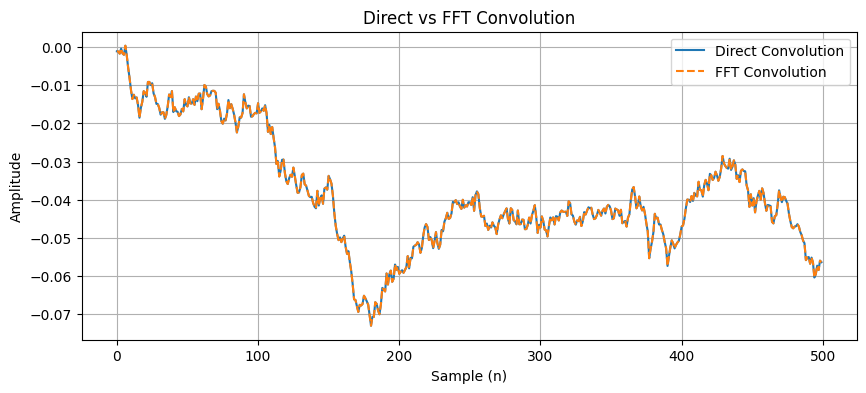

In [71]:
plt.figure(figsize=(10, 4))

plt.plot(y_direct[:500], label="Direct Convolution")
plt.plot(y_fft[:500], "--", label="FFT Convolution")

plt.title("Direct vs FFT Convolution")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

Circular convolution: [3. 2. 3. 2.]


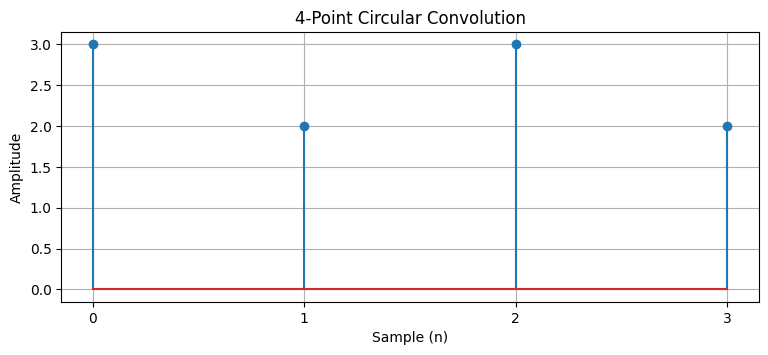

In [72]:
x = np.array([2, 1.5, 1, 0.5])
h = np.array([1, 0, 1, 0])

X = np.fft.fft(x)
H = np.fft.fft(h)

y = np.fft.ifft(X*H).real

print("Circular convolution:", y)

plt.stem(np.arange(4), y)
plt.title("4-Point Circular Convolution")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.xticks(np.arange(4))
plt.grid(True)
plt.show()

## Observation

The direct convolution and FFT-based convolution
produce equivalent results.

Zero-padding prevents circular aliasing and
ensures correct linear convolution.

FFT-based convolution can reduce computational
time for large signals and filters.

The four-point circular convolution produces
the expected result [3, 2, 3, 2].

In [73]:
import pandas as pd

timing_table = pd.DataFrame({
    "Input Size (N)": N_values,
    "Direct DFT (s)": dft_times,
    "Iterative FFT (s)": fft_times,
    "NumPy FFT (s)": numpy_times,
    "Speed-up": np.array(dft_times)/np.array(fft_times)
})

display(timing_table)

speedup = dft_times[-1]/fft_times[-1]

print(f"Speed-up at N = 4096: {speedup:.2f} times")

,Input Size (N),Direct DFT (s),Iterative FFT (s),NumPy FFT (s),Speed-up
0,64,0.004716,0.000694,0.000061,6.793005
1,128,0.001822,0.001151,0.000052,1.583137
2,256,0.005966,0.002212,0.000073,2.697326
3,512,0.027009,0.004316,0.000086,6.257800
4,1024,0.106999,0.013232,0.000110,8.086480
5,2048,0.289136,0.016910,0.000180,17.098113
6,4096,1.002792,0.033684,0.000194,29.770299


Speed-up at N = 4096: 29.77 times


## Analysis Questions

### 1. Estimate the speed-up of iterative FFT over
direct DFT at N = 4096. Why is NumPy FFT faster?

The speed-up is calculated by dividing the direct
DFT execution time by the iterative FFT execution
time at N = 4096.

The measured speed-up is shown in the timing table.

NumPy FFT is faster because it uses optimized
compiled routines and efficient memory management.

### 2. Why is bit reversal needed in the DIT algorithm?

Bit reversal rearranges the input samples into
the correct order for successive butterfly
operations in the iterative DIT FFT algorithm.

This allows the algorithm to produce the final
frequency components in their natural order.

### 3. Why must both sequences be zero-padded
to at least L + M - 1?

Linear convolution produces an output of length:

$$
L+M-1
$$

Zero-padding prevents circular aliasing and
ensures that FFT-based convolution produces
the same result as linear convolution.

### 4. A 4G/5G OFDM receiver performs a 2048-point
FFT every 66.7 microseconds. Estimate the number
of complex multiplications per second.

Given:

$$
N=2048
$$

Complex multiplications per FFT:

$$
\frac{N}{2}\log_2N
$$

$$
=\frac{2048}{2}\times11
$$

$$
=11264
$$

Number of FFT operations per second:

$$
\frac{1}{66.7\times10^{-6}}
\approx14992.5
$$

Complex multiplications per second:

$$
11264\times14992.5
\approx1.689\times10^8
$$

Therefore, approximately 169 million complex
multiplications are required per second.

## Conclusion

This laboratory demonstrated the implementation
of the DFT, bit reversal and iterative radix-2 FFT.

The experiments also demonstrated the effects
of zero-padding and the computational advantages
of FFT-based signal processing.

The FFT provides an efficient approach to
frequency analysis and convolution.

## AI-use Statement

ChatGPT was used to assist with Python code
preparation, mathematical calculations,
algorithm explanations and interpretation
of experimental results.

The experiments were executed in Google Colab.